# Chapter 3 — One-step Schrödinger and Rabi oscillations

With $\hbar=1$ and $\tilde H=\tfrac12(\Omega\sigma_x+\Delta\sigma_z)$, we propagate the state with $U(t)=e^{-i\tilde Ht}$ (diagonalisation) and compare with $P_1(t)=\frac{\Omega^2}{\Omega'^2}\sin^2(\Omega' t/2)$.

*PHY321 Notebook — works offline: numpy and matplotlib are enough.*

In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(321)  # fixed seed: reproducible results

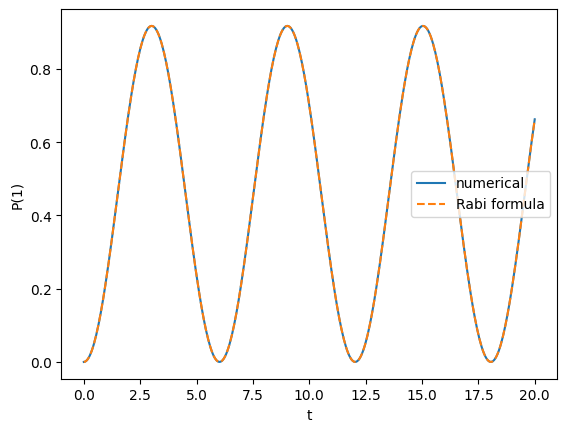

maximum of P1 = 0.9174305675932996 expected 0.9174311926605503


In [2]:
sx = np.array([[0,1],[1,0]]); sz = np.array([[1,0],[0,-1]])
Om, De = 1.0, 0.3
H = 0.5*(Om*sx + De*sz)
E, V = np.linalg.eigh(H)
def U(t): return V @ np.diag(np.exp(-1j*E*t)) @ V.conj().T      # exact propagator
psi0 = np.array([1, 0], dtype=complex)                          # |0>
ts = np.linspace(0, 20, 400)
P1 = np.array([abs((U(t) @ psi0)[1])**2 for t in ts])
Omp = np.hypot(Om, De)
P1_th = (Om/Omp)**2 * np.sin(Omp*ts/2)**2
assert np.allclose(P1, P1_th)
plt.plot(ts, P1, label="numerical"); plt.plot(ts, P1_th, '--', label="Rabi formula")
plt.xlabel('t'); plt.ylabel('P(1)'); plt.legend(); plt.show()
print("maximum of P1 =", P1.max(), "expected", (Om/Omp)**2)

## Resonance

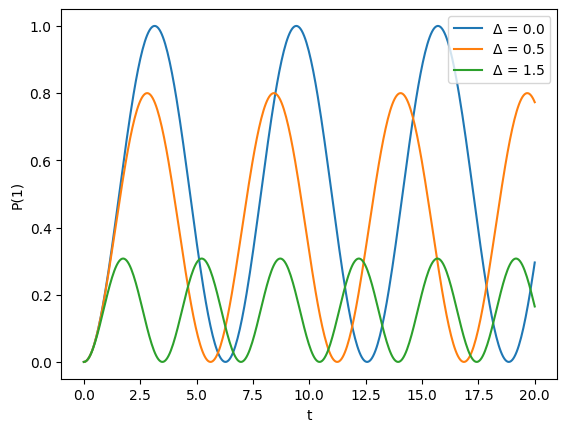

In [3]:
for De in (0.0, 0.5, 1.5):
    H = 0.5*(Om*sx + De*sz); E, V = np.linalg.eigh(H)
    P = [abs((V @ np.diag(np.exp(-1j*E*t)) @ V.conj().T @ psi0)[1])**2 for t in ts]
    plt.plot(ts, P, label=f"Δ = {De}")
plt.xlabel('t'); plt.ylabel('P(1)'); plt.legend(); plt.show()